# <h2 style="color:blue; font-size:50px;"><b><u>Importing nessary libraries</u></b></h2>

In [2]:
import pandas as pd
import numpy as np

# visualization modules
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
#outlier Detection
from sklearn.ensemble import IsolationForest

# PPS
!pip install ppscore
import ppscore as pps

#warnings
import warnings
warnings.filterwarnings('ignore')

Defaulting to user installation because normal site-packages is not writeable


# <h2 style="color:blue; font-size:50px;"><b><u>Load Dataset</u></b></h2>

In [3]:
df = pd.read_csv("adult_with_headers.csv")
print(df.shape)
df.head(10)

(32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
5,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K
6,49,Private,160187,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16,Jamaica,<=50K
7,52,Self-emp-not-inc,209642,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States,>50K
8,31,Private,45781,Masters,14,Never-married,Prof-specialty,Not-in-family,White,Female,14084,0,50,United-States,>50K
9,42,Private,159449,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,5178,0,40,United-States,>50K


In [4]:
df.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [5]:
numerical_cols = df.select_dtypes(include='number').columns
print("Numerical columns:",numerical_cols)

Numerical columns: Index(['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss',
       'hours_per_week'],
      dtype='object')


In [6]:
df.dtypes
numerical_cols = list(df.select_dtypes(include='number').columns)
print("numerical columns:",numerical_cols)
categorical_cols = list(df.select_dtypes(include='object').columns)
print("categorical columns:",categorical_cols)

numerical columns: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
categorical columns: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']


In [7]:
df[['workclass','education','occupation','native_country']].mode()

,workclass,education,occupation,native_country
0,Private,HS-grad,Prof-specialty,United-States


In [8]:
df[['age','capital_gain']].median()

age             37.0
capital_gain     0.0
dtype: float64

In [9]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64

In [10]:
# basic Exploration
print(df.info)
print("\nSummary Statistics")
display(df.describe)
print("\nCategorical Features")
display(df.describe(include='object'))

<bound method DataFrame.info of        age          workclass  fnlwgt    education  education_num  \
0       39          State-gov   77516    Bachelors             13   
1       50   Self-emp-not-inc   83311    Bachelors             13   
2       38            Private  215646      HS-grad              9   
3       53            Private  234721         11th              7   
4       28            Private  338409    Bachelors             13   
...    ...                ...     ...          ...            ...   
32556   27            Private  257302   Assoc-acdm             12   
32557   40            Private  154374      HS-grad              9   
32558   58            Private  151910      HS-grad              9   
32559   22            Private  201490      HS-grad              9   
32560   52       Self-emp-inc  287927      HS-grad              9   

            marital_status          occupation    relationship    race  \
0            Never-married        Adm-clerical   Not-in-family   

<bound method NDFrame.describe of        age          workclass  fnlwgt    education  education_num  \
0       39          State-gov   77516    Bachelors             13   
1       50   Self-emp-not-inc   83311    Bachelors             13   
2       38            Private  215646      HS-grad              9   
3       53            Private  234721         11th              7   
4       28            Private  338409    Bachelors             13   
...    ...                ...     ...          ...            ...   
32556   27            Private  257302   Assoc-acdm             12   
32557   40            Private  154374      HS-grad              9   
32558   58            Private  151910      HS-grad              9   
32559   22            Private  201490      HS-grad              9   
32560   52       Self-emp-inc  287927      HS-grad              9   

            marital_status          occupation    relationship    race  \
0            Never-married        Adm-clerical   Not-in-family 


Categorical Features


,workclass,education,marital_status,occupation,relationship,race,sex,native_country,income
count,32561,32561,32561,32561,32561,32561,32561,32561,32561
unique,9,16,7,15,6,5,2,42,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,22696,10501,14976,4140,13193,27816,21790,29170,24720


# missng Values Analysis

In [11]:
df.replace('?', np.nan, inplace=True)
df.replace('?', np.nan, inplace=True)
missing = df.isnull().sum()
print(missing[missing>0])

Series([], dtype: int64)


In [12]:
for col in df.select_dtypes(include='object').columns:
    df[col].fillna(df[col].mode()[0],inplace=True)

for col in df.select_dtypes(include=np.number).columns:
    df[col].fillna(df[col].median(),inplace=True)

    df.isnull().sum().sum()

# Identify Numerical and Categorical columns

In [13]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.tolist()
print("Numerical columns")
print(num_cols)
print("\nCategorical Columns")
print(cat_cols)

Numerical columns
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical Columns
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']


# Numerical Feature Scaling

In [14]:
# Standard Scaling is suitable for SVM/KNN/Logistic Regression.
# Standard scaler will transforms numericalvalues so that : the mean =1 and starard deviation =1. 
# Scaling in feature engineering is the process of transforming numerical features so they are on the smae scale
# with out scaling , a feature with large values may dominate the model.
#Min Max Scaler is suitable for Nueral Networks.*/
standard_scaler = StandardScaler()
df_standard = df.copy()
df_standard[numerical_cols]=standard_scaler.fit_transform(df_standard[numerical_cols])
df_standard.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,0.030671,State-gov,-1.063611,Bachelors,1.134739,Never-married,Adm-clerical,Not-in-family,White,Male,0.148453,-0.21666,-0.035429,United-States,<=50K
1,0.837109,Self-emp-not-inc,-1.008707,Bachelors,1.134739,Married-civ-spouse,Exec-managerial,Husband,White,Male,-0.145920,-0.21666,-2.222153,United-States,<=50K
2,-0.042642,Private,0.245079,HS-grad,-0.420060,Divorced,Handlers-cleaners,Not-in-family,White,Male,-0.145920,-0.21666,-0.035429,United-States,<=50K
3,1.057047,Private,0.425801,11th,-1.197459,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,-0.145920,-0.21666,-0.035429,United-States,<=50K
4,-0.775768,Private,1.408176,Bachelors,1.134739,Married-civ-spouse,Prof-specialty,Wife,Black,Female,-0.145920,-0.21666,-0.035429,Cuba,<=50K


In [15]:
# min Max Scaler used for Deep Learning , distance based algorithms and values constrained between 0 and 1
minmax_scaler = MinMaxScaler()
df_minmax = df.copy()
df_minmax[numerical_cols] = minmax_scaler.fit_transform(df_minmax[numerical_cols])
df_minmax.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,0.301370,State-gov,0.044302,Bachelors,0.800000,Never-married,Adm-clerical,Not-in-family,White,Male,0.02174,0.0,0.397959,United-States,<=50K
1,0.452055,Self-emp-not-inc,0.048238,Bachelors,0.800000,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.00000,0.0,0.122449,United-States,<=50K
2,0.287671,Private,0.138113,HS-grad,0.533333,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.00000,0.0,0.397959,United-States,<=50K
3,0.493151,Private,0.151068,11th,0.400000,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.00000,0.0,0.397959,United-States,<=50K
4,0.150685,Private,0.221488,Bachelors,0.800000,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.00000,0.0,0.397959,Cuba,<=50K


# Encoding Techniques

# One-Hot Encoding (< 5 Categories)

In [16]:
"""
Encoding is the process of converting categorical (text) data into numerical values.
so that Machine Learning algorithms can understand and process the data.
Most Machine Learning algorythms works with numbers only and cannot process use directly"""


'\nEncoding is the process of converting categorical (text) data into numerical values.\nso that Machine Learning algorithms can understand and process the data.\nMost Machine Learning algorythms works with numbers only and cannot process use directly'

In [17]:

# Label encoding Assigns a unique number to each category
# one hot encoding create separate column for each category we use this technique for unoredred categories
# Ordinal encoding is used when categories have natural order ex:Education>school>UnderGraduate>Graduate>Post Graduate>PHD(Low, Medium, High)
# Binary encoding... First converts categories into numbers and then innto binary values
# Frequency Encoding: Replace each category by its occurence
# Target Encoding: Replace categories with the average target value
# find columns with fewer tha 5 categories:
small_cat_cols = []

for col in categorical_cols:
    if df[col].nunique() < 5:
        small_cat_cols.append(col)

small_cat_cols

['sex', 'income']

In [18]:
df_ohe = pd.get_dummies(
    df,
    columns=small_cat_cols,
    drop_first=True
)

df_ohe.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,capital_loss,hours_per_week,native_country,sex_ Male,income_ >50K
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,2174,0,40,United-States,True,False
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,0,0,13,United-States,True,False
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,0,0,40,United-States,True,False
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,0,0,40,United-States,True,False
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,0,0,40,Cuba,False,False


# Label Encoding (>5 Categories)

In [19]:
label_cols = []

for col in categorical_cols:
    if df[col].nunique() >= 5:
        label_cols.append(col)

label_cols

['workclass',
 'education',
 'marital_status',
 'occupation',
 'relationship',
 'race',
 'native_country']

In [20]:
df_label = df.copy()

le = LabelEncoder()

for col in label_cols:
    df_label[col] = le.fit_transform(df_label[col])

df_label.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,7,77516,9,13,4,1,1,4,Male,2174,0,40,39,<=50K
1,50,6,83311,9,13,2,4,0,4,Male,0,0,13,39,<=50K
2,38,4,215646,11,9,0,6,1,4,Male,0,0,40,39,<=50K
3,53,4,234721,1,7,2,6,0,2,Male,0,0,40,39,<=50K
4,28,4,338409,9,13,2,10,5,2,Female,0,0,40,5,<=50K


# Feature Engineering- Total Capital

In [21]:
df["total_capital"] = (
    df["capital_gain"] -
    df["capital_loss"]
)

df[["capital_gain","capital_loss","total_capital"]].head()

,capital_gain,capital_loss,total_capital
0,2174,0,2174
1,0,0,0
2,0,0,0
3,0,0,0
4,0,0,0


# Feature engineerin - 2. Work intensity

In [22]:
df["work_intensity"] = (
    df["hours_per_week"] / 40
)

#  Feature 3 - Age Group

In [23]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0,25,40,60,100],
    labels=["Young","Adult","Middle_Age","Senior"]
)

df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,total_capital,work_intensity,age_group
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,2174,1.000,Adult
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,0,0.325,Middle_Age
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,0,1.000,Adult
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,0,1.000,Middle_Age
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0,1.000,Adult


# Log Transformation

In [24]:
df["capital_gain"].skew()

np.float64(11.953847687699804)

In [25]:
df["capital_gain_log"] = np.log1p(df["capital_gain"])

df[["capital_gain","capital_gain_log"]].head()

,capital_gain,capital_gain_log
0,2174,7.684784
1,0,0.000000
2,0,0.000000
3,0,0.000000
4,0,0.000000


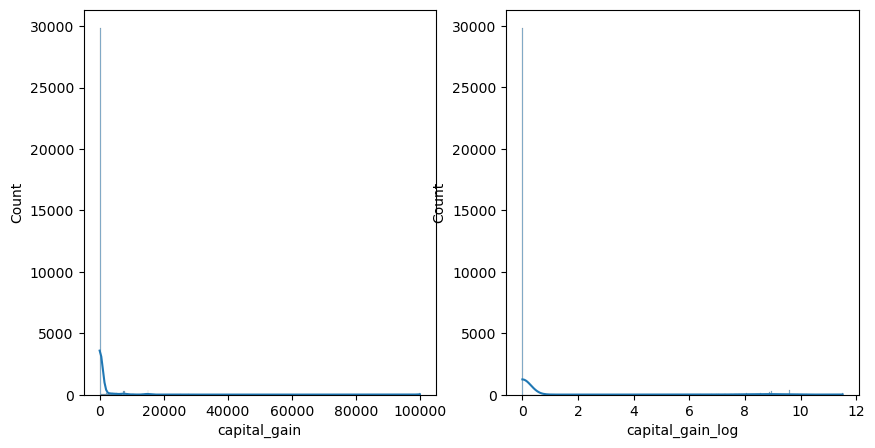

In [26]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
sns.histplot(df["capital_gain"], kde=True)

plt.subplot(1,2,2)
sns.histplot(df["capital_gain_log"], kde=True)

plt.show()

# Outlier Detection using Isolation Forest

In [27]:
numeric_data = df[numerical_cols]

iso = IsolationForest(
    contamination=0.02,
    random_state=42
)

outliers = iso.fit_predict(numeric_data)

df["outlier"] = outliers

df["outlier"].value_counts()

outlier
 1    31909
-1      652
Name: count, dtype: int64

In [28]:
df_clean = df[df["outlier"] == 1]

print("Original Shape:",df.shape)
print("After Removing Outliers:",df_clean.shape)

Original Shape: (32561, 20)
After Removing Outliers: (31909, 20)


# Correlation Analysis

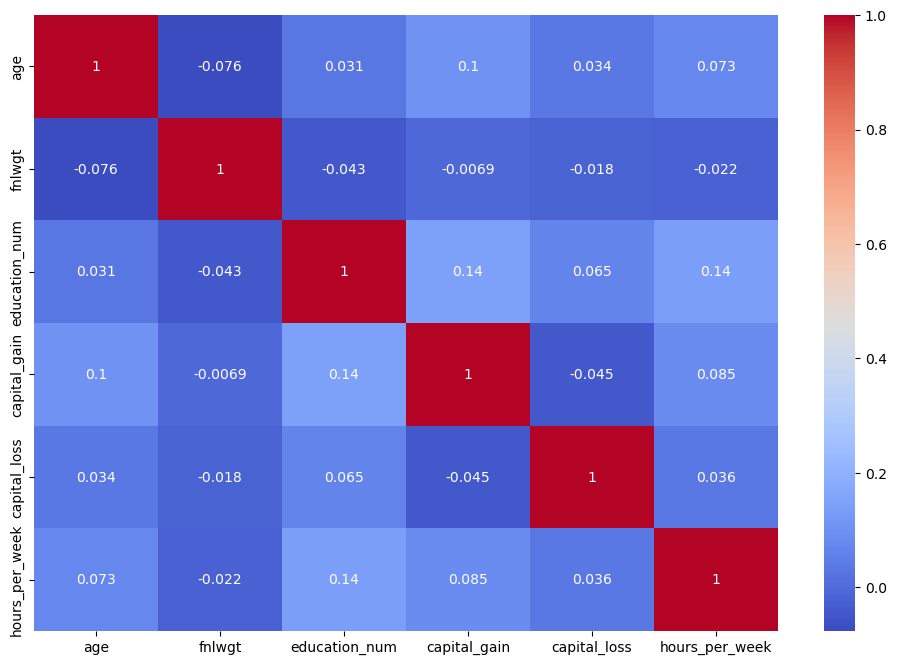

In [29]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df_clean[numerical_cols].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.show()

# PPS Analysis

In [30]:
pip install ppscore

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [31]:
import ppscore as pps

In [32]:
pps_matrix = pps.matrix(df_clean)

pps_matrix.head()

,x,y,ppscore,case,is_valid_score,metric,baseline_score,model_score,model
0,age,age,1.000000,predict_itself,True,None,0.000000,1.000000,None
1,age,workclass,0.015886,classification,True,weighted F1,0.580136,0.586806,DecisionTreeClassifier()
2,age,fnlwgt,0.000000,regression,True,mean absolute error,76365.880400,77529.366217,DecisionTreeRegressor()
3,age,education,0.062851,classification,True,weighted F1,0.200600,0.250843,DecisionTreeClassifier()
4,age,education_num,0.000000,regression,True,mean absolute error,1.829400,1.870954,DecisionTreeRegressor()


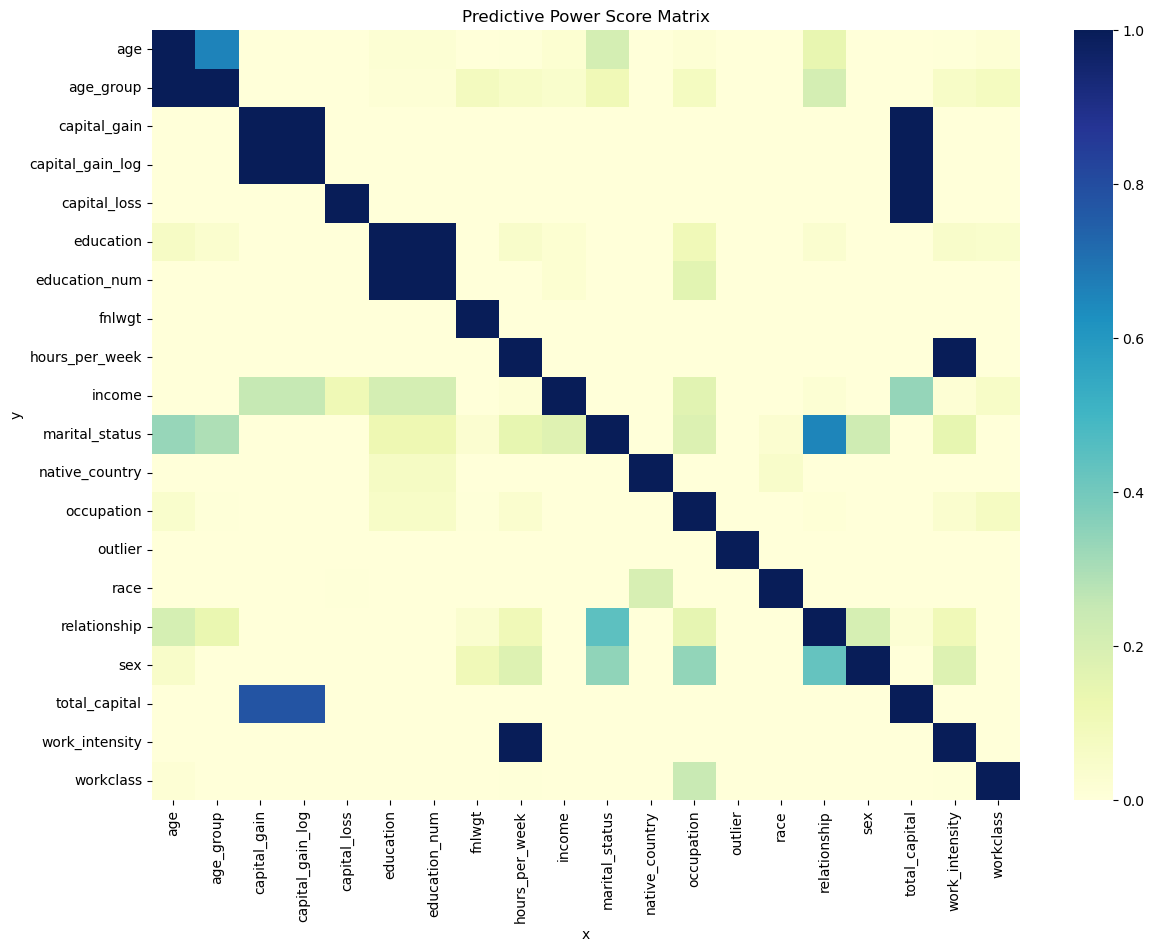

In [33]:
pps_pivot = pps_matrix.pivot(
    columns='x',
    index='y',
    values='ppscore'
)

plt.figure(figsize=(14,10))

sns.heatmap(
    pps_pivot,
    cmap='YlGnBu'
)

plt.title("Predictive Power Score Matrix")

plt.show()